Nama  : Michelle Sianturi
NIM   : 42324062
Prodi : D3 Teknologi Informasi

Praktikum Certan

In [2]:

import pandas as pd
df = pd.read_csv('Text_classification.csv')
print(df.head())

  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


Kode ini terdiri dari tiga baris yang saling berurutan untuk memuat dan melihat isi sebuah dataset.

Baris pertama, import pandas as pd, mengimpor library pandas ke dalam program dan memberinya nama singkat pd. Pandas adalah library Python yang paling umum dipakai untuk mengolah data berbentuk tabel, sehingga dengan nama singkat itu kamu bisa memanggil fungsinya dengan lebih ringkas, misalnya pd.read_csv.

Baris kedua, df = pd.read_csv('Text_classification.csv'), membaca file CSV bernama Text_classification.csv lalu menyimpan isinya ke dalam variabel df. Hasil bacaannya berupa objek DataFrame, yaitu struktur tabel dengan baris dan kolom, mirip lembar kerja di Excel. Dari namanya, file ini kemungkinan berisi data teks beserta label kategorinya untuk keperluan klasifikasi teks. Agar file bisa ditemukan, file tersebut harus berada di folder yang sama dengan kode yang dijalankan, atau kamu perlu menuliskan path lengkapnya.

Baris ketiga, print(df.head()), menampilkan lima baris pertama dari DataFrame tersebut. Fungsi head() memang secara bawaan hanya mengambil lima baris teratas, dan tujuannya adalah memberi gambaran cepat tentang struktur data: nama-nama kolom, jenis isi setiap kolom, dan contoh nilainya. Langkah ini biasanya menjadi tahap awal dalam data understanding, sebelum kamu melanjutkan ke pemeriksaan lain seperti df.info(), df.shape, atau pengecekan nilai kosong.

In [3]:
# Download resource NLTK yang diperlukan
import nltk
nltk.download('punkt_tab')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
# Import library untuk preprocessing
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()
# Fungsi preprocessing teks
def clean_text(text):
 text = text.lower() # Ubah menjadi lowercase
 text = re.sub(r'\d+', '', text) # Hapus angka
 text = text.translate(str.maketrans('', '', string.punctuation)) # Hapus tanda baca
 words = word_tokenize(text) # Tokenisasi
 words = [word for word in words if word not in stopwords.words('english')] # Hapus stopwords
 words = [lemmatizer.lemmatize(word) for word in words] # Lemmatization
 return ' '.join(words)
# Terapkan preprocessing ke teks
df['clean_text'] = df['Message'].apply(clean_text)
# Cek hasil preprocessing
print("\nHasil Preprocessing:\n", df[['Message', 'clean_text']].head())

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...



Hasil Preprocessing:
                                              Message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                          clean_text  
0  go jurong point crazy available bugis n great ...  
1                            ok lar joking wif u oni  
2  free entry wkly comp win fa cup final tkts st ...  
3                u dun say early hor u c already say  
4           nah dont think go usf life around though  


Kode ini melakukan preprocessing (pembersihan) teks pada kolom Message, supaya data teks lebih rapi dan siap dipakai untuk klasifikasi.

Bagian pertama mengunduh resource NLTK yang dibutuhkan lewat nltk.download(). punkt dan punkt_tab dipakai untuk tokenisasi (memecah kalimat menjadi kata), stopwords berisi daftar kata umum yang kurang bermakna seperti "the" atau "is", dan wordnet adalah kamus yang dibutuhkan oleh proses lemmatization. Setelah itu kode mengimpor library pendukung: re untuk pola teks (regular expression), string untuk daftar tanda baca, serta fungsi stopwords, word_tokenize, dan WordNetLemmatizer dari NLTK. Lemmatizer kemudian dibuat sekali dengan lemmatizer = WordNetLemmatizer() agar bisa dipakai berulang.

Inti kodenya ada pada fungsi clean_text(text), yang memproses satu teks melalui enam tahap berurutan. Pertama, text.lower() mengubah semua huruf menjadi huruf kecil agar "Free" dan "free" dianggap sama. Kedua, re.sub(r'\d+', '', text) menghapus semua angka. Ketiga, text.translate(str.maketrans('', '', string.punctuation)) menghapus tanda baca seperti titik, koma, dan tanda seru. Keempat, word_tokenize(text) memecah teks menjadi daftar kata. Kelima, kata-kata yang termasuk stopwords bahasa Inggris dibuang lewat list comprehension. Keenam, lemmatizer.lemmatize(word) mengubah setiap kata ke bentuk dasarnya, misalnya "messages" menjadi "message". Hasil akhirnya digabung kembali menjadi satu string dengan ' '.join(words).

Setelah fungsi didefinisikan, df['clean_text'] = df['Message'].apply(clean_text) menerapkan fungsi tersebut ke setiap baris kolom Message, lalu menyimpan hasilnya di kolom baru bernama clean_text. Kolom asli tetap utuh, sehingga kamu bisa membandingkan sebelum dan sesudah. Terakhir, print(df[['Message', 'clean_text']].head()) menampilkan lima baris pertama dari kedua kolom itu sebagai pengecekan hasil.

In [4]:

# Ubah label dari 'ham'/'spam' menjadi 0/1
df['Category'] = df['Category'].map({'ham': 0, 'spam': 1})
# Cek jumlah masing-masing kelas
print(df['Category'].value_counts())

Category
0    4825
1     747
Name: count, dtype: int64


Kode ini mengubah label kategori yang semula berupa teks menjadi angka, lalu memeriksa berapa banyak data di setiap kelas.

Pada baris pertama, df['Category'].map({'ham': 0, 'spam': 1}) mengambil kolom Category dan mengganti setiap nilainya sesuai kamus (dictionary) yang diberikan: 'ham' (pesan biasa) menjadi 0 dan 'spam' (pesan sampah) menjadi 1. Hasilnya disimpan kembali ke kolom yang sama, sehingga kolom Category yang lama tertimpa. Langkah ini perlu dilakukan karena model machine learning bekerja dengan angka, bukan teks. Ada satu hal yang perlu diperhatikan: jika ada nilai di kolom tersebut yang tidak terdaftar di kamus (misalnya penulisan 'Spam' dengan huruf besar atau ada spasi tambahan), nilainya akan berubah menjadi NaN (kosong), jadi pastikan semua label benar-benar 'ham' atau 'spam'.

Pada baris kedua, print(df['Category'].value_counts()) menghitung berapa kali setiap nilai muncul di kolom Category lalu mencetaknya, diurutkan dari yang paling banyak. Outputnya berupa dua angka: jumlah data berlabel 0 (ham) dan jumlah data berlabel 1 (spam). Pengecekan ini penting untuk melihat apakah datanya seimbang atau tidak. Pada dataset spam, biasanya jumlah ham jauh lebih banyak daripada spam (data tidak seimbang), dan kondisi ini perlu diperhatikan saat melatih model, misalnya dengan menggunakan metrik selain akurasi seperti precision, recall, dan F1-score. Kalau muncul nilai NaN di hasil, itu tanda ada label yang tidak terpetakan dengan benar.

In [5]:
from sklearn.model_selection import train_test_split
# Pisahkan fitur dan label
X = df['clean_text']
y = df['Category']
# Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Kode ini membagi dataset menjadi data latih (training) dan data uji (testing) agar model nantinya bisa dievaluasi dengan data yang belum pernah dilihatnya.

Pada bagian awal, train_test_split diimpor dari sklearn.model_selection. Fungsi ini memang dibuat khusus untuk memecah data secara acak menjadi dua bagian. Setelah itu, data dipisahkan menjadi dua variabel: X = df['clean_text'] adalah fitur, yaitu teks hasil preprocessing yang akan menjadi masukan model, sedangkan y = df['Category'] adalah label atau target yang ingin diprediksi (0 untuk ham dan 1 untuk spam).

Baris train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) melakukan pembagian dengan tiga pengaturan penting. test_size=0.2 berarti 20% data dipakai untuk pengujian dan 80% sisanya untuk pelatihan. random_state=42 mengunci pengacakan sehingga hasil pembagian selalu sama setiap kali kode dijalankan, yang membuat eksperimen bisa direproduksi. Lalu stratify=y memastikan proporsi ham dan spam di data latih dan data uji sama dengan proporsi pada data aslinya. Ini penting karena data spam biasanya tidak seimbang; tanpa stratifikasi, bisa saja data uji kebetulan hanya berisi sedikit spam sehingga evaluasi menjadi tidak adil.

Hasilnya empat variabel: X_train dan y_train untuk melatih model, serta X_test dan y_test untuk menguji performanya. Perlu dicatat bahwa X_train dan X_test masih berupa teks, jadi pada tahap berikutnya teks tersebut perlu diubah menjadi angka, misalnya dengan TF-IDF atau CountVectorizer, sebelum bisa dipakai oleh model.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
# Konversi teks menjadi fitur numerik menggunakan TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1,2), max_features=5000) # Menggunakan bigram
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
print("\nTF-IDF Shape (Train):", X_train_tfidf.shape)


TF-IDF Shape (Train): (4457, 5000)


Kode ini mengubah teks hasil preprocessing menjadi angka dengan metode TF-IDF, karena model machine learning tidak bisa memproses teks mentah.

Pertama, TfidfVectorizer diimpor dari sklearn.feature_extraction.text. TF-IDF (Term Frequency-Inverse Document Frequency) memberi bobot pada setiap kata berdasarkan dua hal: seberapa sering kata itu muncul dalam sebuah pesan (TF), dan seberapa jarang kata itu muncul di seluruh pesan (IDF). Kata yang sering muncul di satu pesan tetapi jarang di pesan lain mendapat bobot tinggi karena dianggap penting untuk membedakan kelas, sedangkan kata yang muncul di hampir semua pesan mendapat bobot rendah.

Baris TfidfVectorizer(ngram_range=(1,2), max_features=5000) membuat objek vectorizer dengan dua pengaturan. ngram_range=(1,2) berarti fitur yang diambil mencakup unigram (satu kata, misalnya "free") dan bigram (dua kata berurutan, misalnya "free entry"). Bigram berguna karena menangkap sedikit konteks urutan kata, misalnya frasa khas spam seperti "call now". Lalu max_features=5000 membatasi jumlah fitur hanya pada 5000 kata atau frasa yang paling sering muncul, supaya ukuran data tidak terlalu besar dan model tidak terbebani fitur yang jarang berguna.

Dua baris berikutnya memiliki perbedaan yang penting. vectorizer.fit_transform(X_train) mempelajari kosakata dan nilai IDF dari data latih, lalu langsung mengubah data latih menjadi matriks angka. Sementara itu, vectorizer.transform(X_test) hanya mengubah data uji memakai kosakata dan IDF yang sudah dipelajari dari data latih, tanpa mempelajari ulang. Hal ini disengaja agar tidak terjadi data leakage, yaitu informasi dari data uji bocor ke proses pelatihan sehingga evaluasi menjadi terlalu optimis.

Terakhir, print("\nTF-IDF Shape (Train):", X_train_tfidf.shape) mencetak ukuran matriks hasilnya dalam bentuk (jumlah baris, jumlah kolom). Jumlah baris sama dengan banyaknya data latih, sedangkan jumlah kolom sama dengan jumlah fitur, yaitu maksimal 5000. Jika kosakata aslinya lebih sedikit dari 5000, jumlah kolomnya akan lebih kecil dari itu. Perlu diketahui juga bahwa hasilnya berupa sparse matrix, yaitu format hemat memori yang hanya menyimpan nilai bukan nol, karena sebagian besar kata tidak muncul di sebuah pesan.

In [7]:
from sklearn.naive_bayes import MultinomialNB
# Inisialisasi model Naïve Bayes
model = MultinomialNB(alpha=0.1)
# Train model
model.fit(X_train_tfidf, y_train)
# Prediksi hasil
y_pred = model.predict(X_test_tfidf)


Kode ini membuat model klasifikasi Naïve Bayes, melatihnya dengan data latih, lalu memakainya untuk memprediksi data uji.

Pertama, MultinomialNB diimpor dari sklearn.naive_bayes. Multinomial Naïve Bayes adalah algoritma berbasis probabilitas yang menghitung peluang sebuah pesan termasuk kelas ham atau spam berdasarkan kata-kata yang ada di dalamnya, dengan asumsi (yang "naif") bahwa setiap kata berdiri sendiri. Varian multinomial ini cocok untuk data teks karena memang dirancang untuk fitur berupa frekuensi atau bobot kata, termasuk nilai TF-IDF seperti yang dihasilkan pada tahap sebelumnya.

Baris model = MultinomialNB(alpha=0.1) membuat objek model dengan parameter alpha=0.1. Parameter ini adalah smoothing (Laplace/Lidstone smoothing), yaitu nilai kecil yang ditambahkan ke setiap hitungan kata agar kata yang tidak pernah muncul di salah satu kelas pada data latih tidak membuat probabilitasnya menjadi nol. Nilai bawaannya adalah 1.0; dengan memakai 0.1, smoothing menjadi lebih ringan sehingga model lebih mempercayai pola yang benar-benar terlihat di data latih. Nilai alpha yang terlalu kecil bisa membuat model terlalu spesifik pada data latih, sedangkan yang terlalu besar membuatnya terlalu umum, jadi nilai ini biasanya dicoba beberapa kali untuk menemukan yang terbaik.

Baris model.fit(X_train_tfidf, y_train) adalah proses pelatihan. Model mempelajari seberapa besar peluang setiap kata atau frasa muncul pada pesan ham dibandingkan pada pesan spam, serta proporsi masing-masing kelas secara keseluruhan. Di sini hanya data latih yang dipakai, sehingga data uji tetap "baru" bagi model.

Terakhir, y_pred = model.predict(X_test_tfidf) memakai model yang sudah dilatih untuk memprediksi label (0 atau 1) setiap pesan di data uji. Hasilnya disimpan di y_pred berupa array. Kode ini belum mencetak apa pun, jadi belum ada output yang muncul. Pada tahap berikutnya, y_pred dibandingkan dengan y_test yang merupakan label sebenarnya, misalnya dengan accuracy_score, classification_report, atau confusion_matrix, untuk mengetahui seberapa baik performa model.

In [8]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# Akurasi
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)
# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.979372197309417

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.98      0.86      0.92       149

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



Kode ini mengevaluasi performa model dengan membandingkan hasil prediksi (y_pred) dengan label yang sebenarnya (y_test).

Pertama, tiga fungsi diimpor dari sklearn.metrics: accuracy_score, classification_report, dan confusion_matrix. Perlu dicatat bahwa confusion_matrix diimpor tetapi belum dipakai di kode ini, jadi tidak berpengaruh pada output. Fungsi itu biasanya dipanggil pada langkah berikutnya untuk melihat rincian jumlah prediksi benar dan salah per kelas.

Baris accuracy = accuracy_score(y_test, y_pred) menghitung akurasi, yaitu perbandingan jumlah prediksi yang benar dengan seluruh data uji. Misalnya, hasil 0.97 berarti 97% pesan diklasifikasikan dengan benar. Hasilnya dicetak lewat print("\nAccuracy:", accuracy). Akurasi memberi gambaran umum yang mudah dipahami, tetapi bisa menyesatkan pada data tidak seimbang. Jika 87% data adalah ham, model yang selalu menebak ham saja sudah mendapat akurasi 87% tanpa pernah mendeteksi spam sama sekali.

Karena itu, kode juga mencetak classification_report(y_test, y_pred), yang menampilkan tiga metrik untuk setiap kelas. Precision menunjukkan dari semua pesan yang diprediksi sebagai suatu kelas, berapa persen yang benar-benar kelas tersebut; untuk spam, precision tinggi berarti sedikit pesan ham biasa yang salah dianggap spam. Recall menunjukkan dari semua pesan yang sebenarnya berkelas tertentu, berapa persen yang berhasil terdeteksi; untuk spam, recall tinggi berarti sedikit spam yang lolos. F1-score adalah rata-rata harmonis antara precision dan recall, sehingga berguna sebagai ringkasan keseimbangan keduanya. Laporan ini juga memuat kolom support, yaitu jumlah data sebenarnya pada tiap kelas di data uji, serta baris rata-rata (macro avg dan weighted avg) di bagian bawah.

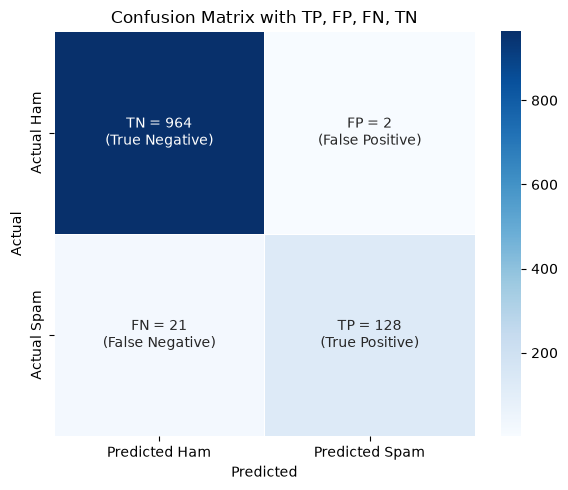

In [10]:
# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Hitung confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Definisi elemen dalam confusion matrix
TN, FP, FN, TP = conf_matrix.ravel()

# Buat dataframe confusion matrix
df_conf_matrix = pd.DataFrame(
    conf_matrix,
    index=['Actual Ham', 'Actual Spam'],
    columns=['Predicted Ham', 'Predicted Spam']
)

# Label untuk TN, FP, FN, TP
labels = np.array([
    [f"TN = {TN}\n(True Negative)",
     f"FP = {FP}\n(False Positive)"],
    [f"FN = {FN}\n(False Negative)",
     f"TP = {TP}\n(True Positive)"]
])

# Plot heatmap dengan keterangan
plt.figure(figsize=(6, 5))

ax = sns.heatmap(
    df_conf_matrix,
    annot=labels,
    fmt='',
    cmap='Blues',
    linewidths=0.5,
    cbar=True
)

# Tambahkan label dan judul
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with TP, FP, FN, TN')

# Tampilkan confusion matrix
plt.tight_layout()
plt.show()

Kode ini menghitung confusion matrix dari hasil prediksi model, lalu menampilkannya sebagai heatmap berwarna lengkap dengan keterangan TN, FP, FN, dan TP di setiap kotak.

Bagian awal mengimpor library yang dibutuhkan: seaborn dan matplotlib.pyplot untuk membuat grafik, numpy untuk membuat array label, pandas untuk membuat tabel, serta confusion_matrix dari sklearn. Perlu dicatat bahwa pandas dan confusion_matrix sebenarnya sudah diimpor di kode sebelumnya, jadi mengimpornya lagi tidak salah, hanya tidak diperlukan jika dijalankan dalam satu notebook yang sama.

Baris conf_matrix = confusion_matrix(y_test, y_pred) menghitung matriks berukuran 2x2 yang membandingkan label sebenarnya dengan hasil prediksi. Lalu TN, FP, FN, TP = conf_matrix.ravel() meratakan matriks itu menjadi satu baris dan memasukkan empat angkanya ke empat variabel secara berurutan. Maknanya: TN (True Negative) adalah ham yang benar diprediksi ham, FP (False Positive) adalah ham yang salah diprediksi spam, FN (False Negative) adalah spam yang salah diprediksi ham (spam yang lolos), dan TP (True Positive) adalah spam yang benar terdeteksi. Urutan ini benar karena label 0 (ham) dianggap kelas negatif dan label 1 (spam) kelas positif.

Selanjutnya, pd.DataFrame(...) mengubah matriks tadi menjadi tabel dengan nama baris Actual Ham dan Actual Spam serta nama kolom Predicted Ham dan Predicted Spam, supaya sumbu heatmap lebih mudah dibaca. Kemudian labels = np.array([...]) membuat array 2x2 berisi teks untuk setiap kotak, misalnya "TN = 950 (True Negative)", dengan \n untuk pindah baris. Teks ini disusun menggunakan f-string agar angka dari variabel TN, FP, FN, dan TP ikut tampil.

Bagian plotting dimulai dengan plt.figure(figsize=(6, 5)) yang menentukan ukuran gambar. Fungsi sns.heatmap(...) kemudian menggambar heatmap dari df_conf_matrix. Parameter annot=labels menampilkan teks buatan sendiri di setiap kotak, dan fmt='' wajib diberikan agar teks tersebut tidak diformat sebagai angka. Selain itu, cmap='Blues' memberi gradasi warna biru (makin banyak data, makin gelap), linewidths=0.5 menambah garis tipis pemisah antarkotak, dan cbar=True menampilkan skala warna di sisi kanan. Terakhir, plt.xlabel, plt.ylabel, dan plt.title menambahkan judul serta nama sumbu, plt.tight_layout() merapikan tata letak, dan plt.show() menampilkan grafik.

Cara membaca hasilnya: diagonal utama (TN dan TP) adalah prediksi yang benar, sehingga semakin gelap dan besar angkanya semakin baik. Sebaliknya, kotak di luar diagonal (FP dan FN) adalah kesalahan model, dan idealnya angkanya kecil. Pada kasus spam, FN biasanya yang paling perlu diperhatikan karena berarti spam lolos tanpa terdeteksi, sedangkan FP berarti pesan penting bisa salah masuk ke folder spam.

In [11]:
# Contoh teks baru
new_texts = ["Congratulations! You won a free trip to Bali.",
 "Hey, are you coming to the party tonight?"]
# Preprocess teks baru
new_texts_clean = [clean_text(text) for text in new_texts]
# Transformasi dengan TF-IDF
new_texts_tfidf = vectorizer.transform(new_texts_clean)
# Prediksi
predictions = model.predict(new_texts_tfidf)
# Output hasil prediksi
for text, label in zip(new_texts, predictions):
 print(f"\nMessage: {text} \nPredicted: {'Spam' if label == 1 else 'Ham'}")


Message: Congratulations! You won a free trip to Bali. 
Predicted: Spam

Message: Hey, are you coming to the party tonight? 
Predicted: Ham


Kode ini mencoba model yang sudah dilatih pada dua kalimat baru, untuk melihat apakah masing-masing diprediksi sebagai spam atau ham.

Bagian pertama membuat daftar new_texts berisi dua contoh pesan. Pesan pertama, "Congratulations! You won a free trip to Bali.", sengaja ditulis dengan gaya khas spam (ucapan selamat, hadiah, kata "free"), sedangkan pesan kedua, "Hey, are you coming to the party tonight?", adalah percakapan biasa. Dengan begitu kamu bisa melihat apakah model membedakan keduanya dengan benar.

Selanjutnya, new_texts_clean = [clean_text(text) for text in new_texts] menjalankan fungsi clean_text yang sama seperti pada data latih ke setiap pesan baru: huruf kecil, hapus angka dan tanda baca, tokenisasi, buang stopwords, lalu lemmatization. Langkah ini wajib sama persis dengan preprocessing saat pelatihan, karena model hanya mengenali pola dari teks yang sudah diproses dengan cara itu. Setelah itu, vectorizer.transform(new_texts_clean) mengubah teks bersih tersebut menjadi vektor TF-IDF. Yang dipakai adalah transform, bukan fit_transform, sehingga vectorizer memakai kosakata dan nilai IDF yang sudah dipelajari dari data latih. Kata atau frasa yang tidak ada di kosakata tersebut akan diabaikan.

Baris predictions = model.predict(new_texts_tfidf) meminta model memprediksi label setiap pesan, hasilnya berupa array berisi 0 (ham) atau 1 (spam). Terakhir, perulangan for text, label in zip(new_texts, predictions) memasangkan setiap pesan asli dengan hasil prediksinya. Di dalamnya, f-string mencetak pesan beserta labelnya, dengan ekspresi 'Spam' if label == 1 else 'Ham' yang mengubah angka 1 menjadi tulisan "Spam" dan angka selain itu menjadi "Ham". Tanda \n membuat setiap hasil tampil di baris baru agar lebih rapi.

Outputnya kemungkinan besar berupa pesan pertama diprediksi Spam dan pesan kedua diprediksi Ham, tetapi ini bergantung pada hasil pelatihan model, sehingga sebaiknya dilihat langsung saat kode dijalankan. Perlu diingat juga bahwa model hanya memberi label tanpa tingkat keyakinan. Jika ingin melihat seberapa yakin model, kamu bisa memakai model.predict_proba(new_texts_tfidf) yang menghasilkan probabilitas untuk tiap kelas.